# Curvas de entrenamiento comparativas de tres modelos

Panel de curvas de entrenamiento (pérdida, pseudo-Dice con EMA, learning rate, tiempo por época y gap de validación frente a entrenamiento) para los tres modelos entrenados: baseline (Dice + CE), clDice v1 y clDice v2.

Los datos por época (epoch, lr, train_loss, val_loss, pseudo_dice, epoch_time_s) se encuentran **incorporados en el propio notebook**, extraídos de los logs de entrenamiento de los notebooks 11, 12 y 12b. Por ello, puede ejecutarse en cualquier entorno (Colab, local) sin conexión a Drive ni GPU. Para añadir un modelo o repetir un entrenamiento, basta con sustituir el bloque CSV correspondiente.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO

plt.rcParams["font.family"] = "DejaVu Sans"


## 1. Datos de entrenamiento (incorporados)

Cada bloque es el CSV con una fila por época (100 épocas × 3 modelos), extraído de los logs impresos por nnU-Net durante el entrenamiento (notebooks 11, 12 y 12b).


In [2]:
CSV_BASELINE = """epoch,lr,train_loss,val_loss,pseudo_dice,epoch_time_s
0,0.01,-0.2244,-0.4654,0.5366,160.15
1,0.00991,-0.4736,-0.506,0.5727,42.8
2,0.00982,-0.5194,-0.5545,0.6308,45.83
3,0.00973,-0.5456,-0.5987,0.6622,46.56
4,0.00964,-0.5686,-0.5698,0.6066,45.59
5,0.00955,-0.5723,-0.6209,0.6671,45.18
6,0.00946,-0.5933,-0.6413,0.6844,44.62
7,0.00937,-0.5892,-0.5935,0.6576,46.85
8,0.00928,-0.5949,-0.6528,0.7081,45.25
9,0.00919,-0.6103,-0.5907,0.6595,45.79
10,0.0091,-0.614,-0.6678,0.7179,46.66
11,0.009,-0.6326,-0.6625,0.7087,44.12
12,0.00891,-0.6276,-0.6597,0.7115,43.29
13,0.00882,-0.6377,-0.6569,0.6988,44.22
14,0.00873,-0.6374,-0.6735,0.7225,46.73
15,0.00864,-0.6355,-0.678,0.7224,46.87
16,0.00855,-0.6488,-0.6705,0.7104,44.77
17,0.00846,-0.6418,-0.6681,0.7166,45.14
18,0.00836,-0.6618,-0.6668,0.7191,45.37
19,0.00827,-0.6644,-0.6659,0.7252,44.3
20,0.00818,-0.6485,-0.6946,0.7428,44.76
21,0.00809,-0.6645,-0.6894,0.7348,44.82
22,0.008,-0.6621,-0.6708,0.7137,38.43
23,0.0079,-0.6653,-0.7044,0.7604,48.37
24,0.00781,-0.6564,-0.6879,0.7424,44.97
25,0.00772,-0.658,-0.6936,0.7372,45.88
26,0.00763,-0.681,-0.7042,0.7492,45.49
27,0.00753,-0.6885,-0.6821,0.7269,45.15
28,0.00744,-0.6706,-0.6972,0.7352,44.65
29,0.00735,-0.6782,-0.7064,0.7441,47.89
30,0.00725,-0.6971,-0.6906,0.7408,43.81
31,0.00716,-0.6607,-0.6782,0.7089,46.06
32,0.00707,-0.6868,-0.6882,0.7365,40.27
33,0.00697,-0.6791,-0.7129,0.7598,45.61
34,0.00688,-0.667,-0.7315,0.765,46.89
35,0.00679,-0.697,-0.6959,0.7392,47.36
36,0.00669,-0.6953,-0.7343,0.7717,46.03
37,0.0066,-0.6887,-0.6985,0.7339,46.85
38,0.0065,-0.7019,-0.7323,0.7684,40.27
39,0.00641,-0.698,-0.7185,0.7551,44.98
40,0.00631,-0.6941,-0.742,0.773,44.59
41,0.00622,-0.696,-0.7232,0.775,44.82
42,0.00612,-0.6905,-0.7286,0.7734,46.35
43,0.00603,-0.6833,-0.7217,0.7682,45.43
44,0.00593,-0.7147,-0.7347,0.7657,46.94
45,0.00584,-0.6863,-0.7176,0.7454,45.66
46,0.00574,-0.7017,-0.7526,0.7842,39.66
47,0.00565,-0.7151,-0.7023,0.7337,45.7
48,0.00555,-0.7025,-0.713,0.758,40.79
49,0.00546,-0.7009,-0.7239,0.7526,42.31
50,0.00536,-0.7001,-0.7147,0.7508,40.72
51,0.00526,-0.7172,-0.7354,0.7629,39.46
52,0.00517,-0.7089,-0.7059,0.7496,41.04
53,0.00507,-0.7293,-0.7256,0.7583,39.84
54,0.00497,-0.7187,-0.7381,0.7801,41.64
55,0.00487,-0.7169,-0.7145,0.7581,43.44
56,0.00478,-0.703,-0.7237,0.7597,43.67
57,0.00468,-0.7203,-0.736,0.7688,45.27
58,0.00458,-0.7073,-0.7063,0.7465,45.08
59,0.00448,-0.7124,-0.7483,0.7765,39.99
60,0.00438,-0.7307,-0.7168,0.7545,44.48
61,0.00429,-0.7191,-0.7566,0.789,39.7
62,0.00419,-0.7167,-0.7671,0.7956,47.88
63,0.00409,-0.7229,-0.7289,0.7592,46.26
64,0.00399,-0.718,-0.7259,0.7725,41.01
65,0.00389,-0.7292,-0.738,0.7648,45.07
66,0.00379,-0.7292,-0.7361,0.7626,41.03
67,0.00369,-0.7345,-0.7282,0.7659,39.7
68,0.00359,-0.7197,-0.7169,0.7514,40.97
69,0.00349,-0.724,-0.7468,0.7779,39.51
70,0.00338,-0.7249,-0.7464,0.7752,40.01
71,0.00328,-0.7305,-0.7348,0.7734,44.74
72,0.00318,-0.7212,-0.7346,0.7708,46.58
73,0.00308,-0.7199,-0.751,0.7851,47.43
74,0.00297,-0.731,-0.7553,0.7853,45.04
75,0.00287,-0.7324,-0.7627,0.7891,47.21
76,0.00277,-0.7342,-0.7506,0.7952,44.44
77,0.00266,-0.733,-0.7376,0.7735,46.73
78,0.00256,-0.7388,-0.7373,0.7708,39.26
79,0.00245,-0.7372,-0.7525,0.7868,41.45
80,0.00235,-0.7307,-0.7293,0.7751,46.5
81,0.00224,-0.7452,-0.7596,0.7932,40.16
82,0.00214,-0.7342,-0.7546,0.7832,44.46
83,0.00203,-0.7412,-0.7687,0.7959,46.99
84,0.00192,-0.7458,-0.7481,0.7829,45.56
85,0.00181,-0.7455,-0.7517,0.7768,45.38
86,0.0017,-0.7423,-0.7468,0.7828,42.5
87,0.00159,-0.7497,-0.732,0.7694,45.34
88,0.00148,-0.7394,-0.7784,0.7987,39.48
89,0.00137,-0.7494,-0.7451,0.7783,45.01
90,0.00126,-0.7534,-0.7404,0.7789,40.03
91,0.00115,-0.7538,-0.7562,0.7933,41.28
92,0.00103,-0.7387,-0.7507,0.7913,45.41
93,0.00091,-0.7437,-0.7677,0.8038,45.27
94,0.00079,-0.7468,-0.7613,0.7957,46.51
95,0.00067,-0.7475,-0.7671,0.7924,44.93
96,0.00055,-0.7492,-0.7626,0.7983,46.17
97,0.00043,-0.7567,-0.7553,0.7797,44.72
98,0.0003,-0.7517,-0.7672,0.8015,41.13
99,0.00016,-0.7704,-0.7745,0.7991,46.1
"""

CSV_CLDICE_V1 = """epoch,lr,train_loss,val_loss,pseudo_dice,epoch_time_s
0,0.01,-0.0413,-0.2726,0.4659,301.1
1,0.00991,-0.3767,-0.4691,0.6155,109.47
2,0.00982,-0.4526,-0.5036,0.6382,86.89
3,0.00973,-0.4619,-0.4724,0.6078,72.26
4,0.00964,-0.4775,-0.5055,0.6323,71.56
5,0.00955,-0.5099,-0.4754,0.6047,72.58
6,0.00946,-0.5178,-0.5333,0.6576,69.92
7,0.00937,-0.5443,-0.5315,0.6567,67.84
8,0.00928,-0.5506,-0.6035,0.7001,68.29
9,0.00919,-0.5806,-0.6064,0.7041,69.01
10,0.0091,-0.5648,-0.6317,0.7265,68.74
11,0.009,-0.5754,-0.6299,0.7228,68.5
12,0.00891,-0.5922,-0.6082,0.7177,68.34
13,0.00882,-0.5969,-0.6041,0.7074,69.26
14,0.00873,-0.585,-0.6343,0.7208,68.3
15,0.00864,-0.6053,-0.64,0.7236,68.75
16,0.00855,-0.5891,-0.6232,0.7164,68.27
17,0.00846,-0.5986,-0.5823,0.6856,68.63
18,0.00836,-0.5875,-0.5836,0.6809,67.92
19,0.00827,-0.6066,-0.5917,0.7057,68.41
20,0.00818,-0.6122,-0.6186,0.7281,68.81
21,0.00809,-0.6137,-0.651,0.7317,68.27
22,0.008,-0.6196,-0.6354,0.7233,68.64
23,0.0079,-0.6076,-0.6057,0.699,68.78
24,0.00781,-0.6116,-0.6554,0.7379,68.92
25,0.00772,-0.6185,-0.6368,0.7338,68.31
26,0.00763,-0.609,-0.6368,0.7272,68.31
27,0.00753,-0.6229,-0.6291,0.7201,68.01
28,0.00744,-0.6203,-0.5707,0.6804,68.23
29,0.00735,-0.6213,-0.6721,0.7493,65.13
30,0.00725,-0.6333,-0.6532,0.7514,68.17
31,0.00716,-0.6415,-0.6948,0.7727,69.52
32,0.00707,-0.6312,-0.696,0.771,68.2
33,0.00697,-0.6517,-0.6474,0.7347,67.89
34,0.00688,-0.6587,-0.6912,0.7697,68.27
35,0.00679,-0.6278,-0.6953,0.7629,69.76
36,0.00669,-0.6424,-0.6901,0.7592,68.61
37,0.0066,-0.6677,-0.633,0.7419,68.98
38,0.0065,-0.6608,-0.632,0.7213,68.29
39,0.00641,-0.6409,-0.7057,0.7808,65.11
40,0.00631,-0.6591,-0.6939,0.7648,69.19
41,0.00622,-0.66,-0.7033,0.7681,68.49
42,0.00612,-0.6563,-0.6662,0.7478,68.78
43,0.00603,-0.6684,-0.6965,0.7701,69.1
44,0.00593,-0.6703,-0.6841,0.7613,68.63
45,0.00584,-0.6604,-0.6535,0.7285,68.73
46,0.00574,-0.6545,-0.6955,0.7685,65.13
47,0.00565,-0.6695,-0.6832,0.7553,67.91
48,0.00555,-0.6684,-0.6835,0.7603,68.33
49,0.00546,-0.674,-0.7159,0.7873,69.05
50,0.00536,-0.6728,-0.6856,0.7562,68.95
51,0.00526,-0.6721,-0.6948,0.7702,67.87
52,0.00517,-0.6834,-0.7095,0.7753,69.15
53,0.00507,-0.6894,-0.7236,0.7879,68.83
54,0.00497,-0.674,-0.7107,0.7672,68.68
55,0.00487,-0.6829,-0.6796,0.7474,68.6
56,0.00478,-0.6792,-0.6784,0.7579,65.38
57,0.00468,-0.6577,-0.6947,0.7672,65.97
58,0.00458,-0.681,-0.6969,0.777,65.31
59,0.00448,-0.6831,-0.7117,0.7772,68.59
60,0.00438,-0.6947,-0.6943,0.7766,68.64
61,0.00429,-0.6709,-0.7014,0.7682,68.75
62,0.00419,-0.6871,-0.7286,0.7845,68.52
63,0.00409,-0.6928,-0.7127,0.7734,68.78
64,0.00399,-0.6726,-0.7183,0.7812,68.98
65,0.00389,-0.6962,-0.7057,0.781,68.21
66,0.00379,-0.696,-0.7292,0.7951,68.17
67,0.00369,-0.6884,-0.7167,0.777,68.58
68,0.00359,-0.6972,-0.7183,0.7815,68.35
69,0.00349,-0.711,-0.7166,0.7908,69.09
70,0.00338,-0.6908,-0.713,0.781,68.75
71,0.00328,-0.7043,-0.7201,0.7917,68.82
72,0.00318,-0.7055,-0.6977,0.7618,68.62
73,0.00308,-0.7006,-0.7311,0.796,65.27
74,0.00297,-0.7079,-0.7141,0.7843,68.33
75,0.00287,-0.6926,-0.7141,0.7807,69.1
76,0.00277,-0.696,-0.6921,0.7729,68.77
77,0.00266,-0.6982,-0.6881,0.7608,65.19
78,0.00256,-0.6991,-0.7122,0.7742,65.57
79,0.00245,-0.7207,-0.7254,0.791,65.12
80,0.00235,-0.7066,-0.7018,0.7749,65.19
81,0.00224,-0.7151,-0.7155,0.781,65.05
82,0.00214,-0.7117,-0.7098,0.7871,65.03
83,0.00203,-0.6963,-0.7017,0.7636,64.9
84,0.00192,-0.7047,-0.7412,0.7997,65.46
85,0.00181,-0.7122,-0.7162,0.7881,68.51
86,0.0017,-0.7177,-0.6951,0.7707,68.4
87,0.00159,-0.71,-0.7158,0.7774,65.68
88,0.00148,-0.7143,-0.7157,0.779,65.34
89,0.00137,-0.7074,-0.6949,0.7697,65.44
90,0.00126,-0.6856,-0.7587,0.8047,65.27
91,0.00115,-0.7176,-0.7389,0.7949,68.17
92,0.00103,-0.7159,-0.754,0.8086,68.62
93,0.00091,-0.7301,-0.7321,0.7974,69.63
94,0.00079,-0.7205,-0.7195,0.7865,68.95
95,0.00067,-0.7321,-0.7108,0.7772,67.56
96,0.00055,-0.7234,-0.7262,0.7962,65.21
97,0.00043,-0.7195,-0.732,0.7938,68.74
98,0.0003,-0.7144,-0.7149,0.7848,68.85
99,0.00016,-0.7313,-0.7462,0.8047,65.38
"""

CSV_CLDICE_V2 = """epoch,lr,train_loss,val_loss,pseudo_dice,epoch_time_s
0,0.01,-0.2457,-0.4381,0.5241,223.83
1,0.00991,-0.4423,-0.4938,0.5677,62.48
2,0.00982,-0.5152,-0.5754,0.6491,56.67
3,0.00973,-0.5094,-0.5514,0.6174,53.47
4,0.00964,-0.5357,-0.6011,0.6852,50.91
5,0.00955,-0.5504,-0.5751,0.6647,51.06
6,0.00946,-0.5682,-0.5826,0.6611,50.68
7,0.00937,-0.5659,-0.6021,0.6902,50.51
8,0.00928,-0.573,-0.5985,0.6994,49.75
9,0.00919,-0.5612,-0.5966,0.694,49.58
10,0.0091,-0.5884,-0.5684,0.6652,50.58
11,0.009,-0.564,-0.6404,0.7244,50.26
12,0.00891,-0.5514,-0.5712,0.6934,50.12
13,0.00882,-0.5822,-0.644,0.7353,50.13
14,0.00873,-0.5931,-0.6488,0.736,50.28
15,0.00864,-0.6081,-0.6189,0.713,50.07
16,0.00855,-0.6027,-0.6807,0.7477,50.1
17,0.00846,-0.6036,-0.6167,0.7117,50.37
18,0.00836,-0.6122,-0.6751,0.757,49.79
19,0.00827,-0.6166,-0.6635,0.7436,50.05
20,0.00818,-0.615,-0.6385,0.7279,51.28
21,0.00809,-0.6185,-0.6178,0.7171,49.88
22,0.008,-0.6214,-0.6846,0.7589,49.78
23,0.0079,-0.6355,-0.6937,0.761,50.45
24,0.00781,-0.6278,-0.6809,0.7532,50.2
25,0.00772,-0.6364,-0.6597,0.7347,50.41
26,0.00763,-0.6426,-0.6722,0.759,50.39
27,0.00753,-0.6225,-0.6014,0.6942,49.94
28,0.00744,-0.6342,-0.6802,0.7532,46.28
29,0.00735,-0.6515,-0.6576,0.7415,50.99
30,0.00725,-0.6538,-0.6902,0.7677,49.42
31,0.00716,-0.6372,-0.5987,0.685,50.45
32,0.00707,-0.6479,-0.6726,0.7457,46.31
33,0.00697,-0.6471,-0.6453,0.7432,46.32
34,0.00688,-0.6491,-0.7009,0.77,49.64
35,0.00679,-0.6808,-0.6849,0.7525,49.88
36,0.00669,-0.6655,-0.6974,0.7689,49.96
37,0.0066,-0.6637,-0.6832,0.7568,50.48
38,0.0065,-0.6611,-0.6331,0.706,50.34
39,0.00641,-0.6697,-0.7044,0.7694,46.54
40,0.00631,-0.6644,-0.6559,0.7399,50.7
41,0.00622,-0.6635,-0.6901,0.7594,50.98
42,0.00612,-0.6633,-0.7019,0.7649,50.89
43,0.00603,-0.6774,-0.6729,0.7461,50.29
44,0.00593,-0.6734,-0.7086,0.7813,50.05
45,0.00584,-0.6679,-0.6781,0.7623,50.2
46,0.00574,-0.6731,-0.6771,0.7407,50.98
47,0.00565,-0.6832,-0.7176,0.7702,46.74
48,0.00555,-0.6687,-0.6745,0.7507,50.24
49,0.00546,-0.6634,-0.7227,0.7833,50.68
50,0.00536,-0.6791,-0.6787,0.7489,50.08
51,0.00526,-0.6841,-0.6782,0.7498,46.63
52,0.00517,-0.6967,-0.7012,0.7689,46.7
53,0.00507,-0.6732,-0.6813,0.7501,50.17
54,0.00497,-0.6819,-0.7006,0.7663,46.46
55,0.00487,-0.6764,-0.7203,0.7738,50.79
56,0.00478,-0.6837,-0.73,0.7899,50.69
57,0.00468,-0.6984,-0.6996,0.7668,50.83
58,0.00458,-0.6958,-0.7408,0.7983,50.6
59,0.00448,-0.6881,-0.7004,0.7716,50.17
60,0.00438,-0.6906,-0.7256,0.7872,50.51
61,0.00429,-0.6934,-0.7051,0.7721,50.74
62,0.00419,-0.6881,-0.7388,0.789,50.36
63,0.00409,-0.7008,-0.7119,0.7778,50.49
64,0.00399,-0.6864,-0.7045,0.7668,50.3
65,0.00389,-0.684,-0.732,0.7908,46.64
66,0.00379,-0.678,-0.7539,0.8031,50.07
67,0.00369,-0.7032,-0.7354,0.7907,50.4
68,0.00359,-0.7099,-0.7276,0.7885,49.66
69,0.00349,-0.7119,-0.7148,0.7806,49.96
70,0.00338,-0.7002,-0.706,0.7775,50.27
71,0.00328,-0.7031,-0.6978,0.772,46.36
72,0.00318,-0.6989,-0.7384,0.7957,46.6
73,0.00308,-0.6897,-0.7254,0.7856,50.16
74,0.00297,-0.7124,-0.7255,0.778,50.65
75,0.00287,-0.7028,-0.7463,0.8016,46.67
76,0.00277,-0.7142,-0.7507,0.7973,49.98
77,0.00266,-0.702,-0.7483,0.8013,50.32
78,0.00256,-0.7102,-0.7401,0.8017,50.26
79,0.00245,-0.7017,-0.728,0.7855,49.78
80,0.00235,-0.7071,-0.6724,0.7447,46.48
81,0.00224,-0.7161,-0.7529,0.8007,46.56
82,0.00214,-0.6976,-0.7316,0.7901,46.39
83,0.00203,-0.7234,-0.7316,0.7905,47.24
84,0.00192,-0.6939,-0.7333,0.7922,46.64
85,0.00181,-0.7136,-0.7698,0.8105,46.47
86,0.0017,-0.719,-0.702,0.7735,49.9
87,0.00159,-0.712,-0.7162,0.7794,46.61
88,0.00148,-0.7185,-0.7144,0.7769,46.48
89,0.00137,-0.7224,-0.7128,0.7809,46.55
90,0.00126,-0.711,-0.7433,0.7949,46.3
91,0.00115,-0.7269,-0.7236,0.7958,46.29
92,0.00103,-0.7254,-0.7001,0.7712,46.32
93,0.00091,-0.7273,-0.7206,0.7775,46.46
94,0.00079,-0.7126,-0.7172,0.7828,46.31
95,0.00067,-0.7189,-0.7149,0.7862,46.35
96,0.00055,-0.7307,-0.7382,0.7988,46.37
97,0.00043,-0.7216,-0.7289,0.7828,46.34
98,0.0003,-0.7321,-0.7462,0.7885,46.29
99,0.00016,-0.7251,-0.7338,0.787,46.26
"""

dfs = {
    "Baseline (Dice+CE)": pd.read_csv(StringIO(CSV_BASELINE)),
    "clDice v1": pd.read_csv(StringIO(CSV_CLDICE_V1)),
    "clDice v2": pd.read_csv(StringIO(CSV_CLDICE_V2)),
}

for label, df in dfs.items():
    print(f"{label}: {len(df)} epocas, columnas: {list(df.columns)}")


Baseline (Dice+CE): 100 epocas, columnas: ['epoch', 'lr', 'train_loss', 'val_loss', 'pseudo_dice', 'epoch_time_s']
clDice v1: 100 epocas, columnas: ['epoch', 'lr', 'train_loss', 'val_loss', 'pseudo_dice', 'epoch_time_s']
clDice v2: 100 epocas, columnas: ['epoch', 'lr', 'train_loss', 'val_loss', 'pseudo_dice', 'epoch_time_s']


## 2. Suavizado EMA

Media móvil exponencial con α = 0.9, la misma que emplea nnU-Net internamente para seleccionar el mejor checkpoint. Aquí se aplica con fines de visualización sobre el pseudo-Dice, que presenta mucho ruido de una época a otra.


In [3]:
def ema(series, alpha=0.9):
    out = []
    prev = None
    for v in series:
        prev = v if prev is None else alpha * prev + (1 - alpha) * v
        out.append(prev)
    return np.array(out)


## 3. Panel de curvas comparativas (6 gráficas)


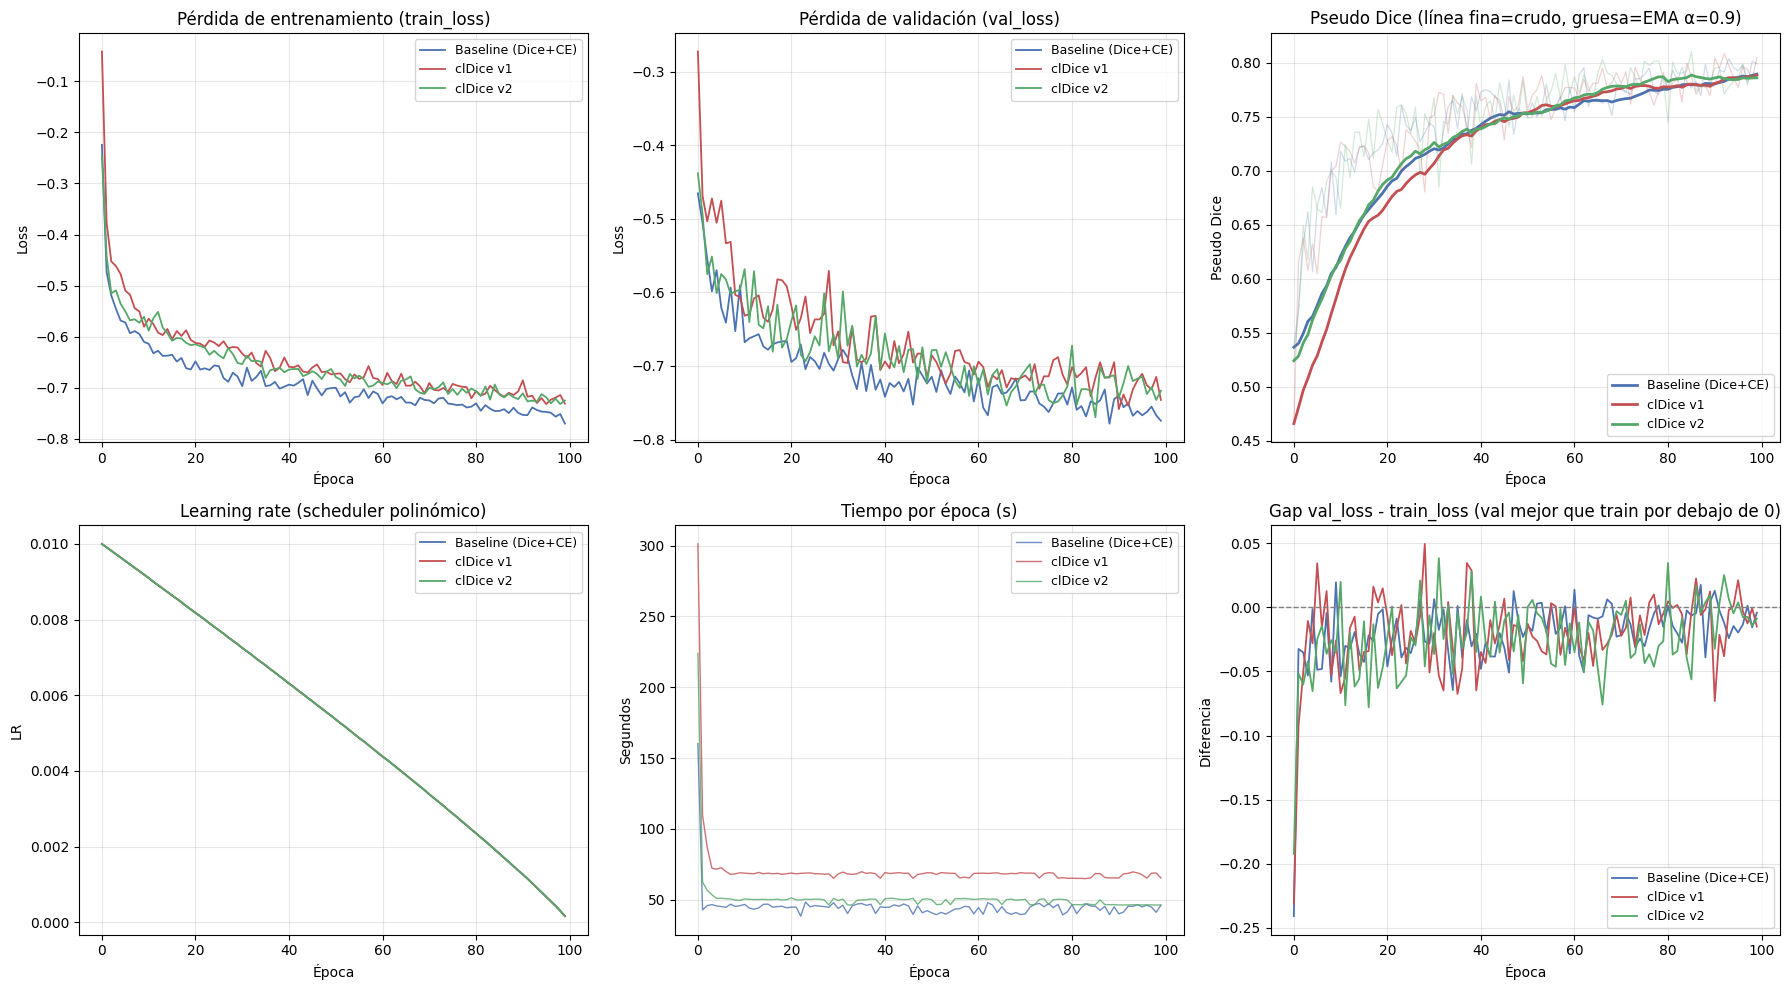

Guardado: curvas_comparativas_3modelos.png


In [4]:
colors = {"Baseline (Dice+CE)": "#4C72B0", "clDice v1": "#C44E52", "clDice v2": "#55A868"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Pérdida de entrenamiento
ax = axes[0, 0]
for label, df in dfs.items():
    ax.plot(df["epoch"], df["train_loss"], color=colors[label], label=label, linewidth=1.3)
ax.set_title("Pérdida de entrenamiento (train_loss)")
ax.set_xlabel("Época"); ax.set_ylabel("Loss")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 2. Pérdida de validación
ax = axes[0, 1]
for label, df in dfs.items():
    ax.plot(df["epoch"], df["val_loss"], color=colors[label], label=label, linewidth=1.3)
ax.set_title("Pérdida de validación (val_loss)")
ax.set_xlabel("Época"); ax.set_ylabel("Loss")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 3. Pseudo-Dice (crudo y EMA)
ax = axes[0, 2]
for label, df in dfs.items():
    ax.plot(df["epoch"], df["pseudo_dice"], color=colors[label], alpha=0.25, linewidth=0.9)
    ax.plot(df["epoch"], ema(df["pseudo_dice"].values), color=colors[label], label=label, linewidth=2)
ax.set_title("Pseudo Dice (línea fina=crudo, gruesa=EMA α=0.9)")
ax.set_xlabel("Época"); ax.set_ylabel("Pseudo Dice")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 4. Learning rate
ax = axes[1, 0]
for label, df in dfs.items():
    ax.plot(df["epoch"], df["lr"], color=colors[label], label=label, linewidth=1.3)
ax.set_title("Learning rate (scheduler polinómico)")
ax.set_xlabel("Época"); ax.set_ylabel("LR")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 5. Tiempo por época
ax = axes[1, 1]
for label, df in dfs.items():
    ax.plot(df["epoch"], df["epoch_time_s"], color=colors[label], label=label, linewidth=1.0, alpha=0.8)
ax.set_title("Tiempo por época (s)")
ax.set_xlabel("Época"); ax.set_ylabel("Segundos")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 6. Gap de pérdida (validación - entrenamiento)
ax = axes[1, 2]
for label, df in dfs.items():
    gap = df["val_loss"] - df["train_loss"]
    ax.plot(df["epoch"], gap, color=colors[label], label=label, linewidth=1.3)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Gap val_loss - train_loss (val mejor que train por debajo de 0)")
ax.set_xlabel("Época"); ax.set_ylabel("Diferencia")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("curvas_comparativas_3modelos.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: curvas_comparativas_3modelos.png")


## 4. Resumen numérico de la eficiencia del entrenamiento


In [5]:
summary_rows = []
for label, df in dfs.items():
    summary_rows.append({
        "Modelo": label,
        "Tiempo total (h)": df["epoch_time_s"].sum() / 3600,
        "Pseudo-Dice últimas 5 épocas (media)": df["pseudo_dice"].iloc[-5:].mean(),
        "Mejor Pseudo-Dice puntual": df["pseudo_dice"].max(),
        "Tiempo medio/época (s)": df["epoch_time_s"].mean(),
    })

summary = pd.DataFrame(summary_rows).set_index("Modelo").round(4)
summary


,Tiempo total (h),Pseudo-Dice últimas 5 épocas (media),Mejor Pseudo-Dice puntual,Tiempo medio/época (s)
Modelo,,,,
Baseline (Dice+CE),1.2590,0.7942,0.8038,45.3246
clDice v1,1.9705,0.7913,0.8086,70.9391
clDice v2,1.4187,0.7887,0.8105,51.0729


## 5. Nota metodológica

El pseudo-Dice que calcula nnU-Net durante el entrenamiento es una estimación rápida y ruidosa (sobre parches, sin post-procesado ni reconstrucción de la imagen completa). Resulta útil para monitorizar que el entrenamiento progresa de forma estable (ausencia de sobreajuste y convergencia razonable), pero no para determinar qué modelo es mejor. Esa comparación se basa en la evaluación final con Dice y clDice calculados sobre la imagen completa reconstruida (notebook 13).
